<a href="https://colab.research.google.com/github/Osama-Abdulhamid/CommerceRadar/blob/main/VoltSwap_Smart_EV_Battery_Swapping_OOP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Object-Oriented System Design & Implementation
## **VoltSwap — Smart EV Battery-Swapping Kiosk Network for Delivery Fleets & Micro-Mobility**

**Deliverables Included in This Notebook:**
1. **Business Case Description:** Real-world micro-mobility energy problem, proposed object-oriented software solution, and expected business impact.
2. **UML Class Diagram:** Complete architectural class diagram showing 8 classes, attributes, methods, visibility symbols, multiplicities, and all four core OOP relationships (*Inheritance*, *Composition*, *Aggregation*, and *Association*).
3. **UML Sequence Diagram:** Chronological interaction diagram illustrating the 60-second smart battery swap, atomic bay locking, State-of-Charge (SoC) telemetry logging, polymorphic energy tariff calculation, and instant digital wallet billing.
4. **Python Implementation & Simulation:** Full Object-Oriented Python implementation of all classes in the diagram, complete with a working multi-scenario simulation and verified outputs.

## 1. Business Case Description

### 1.1 Business Domain
**Green Micro-Mobility & Smart Electric Vehicle (EV) Battery-Swapping Infrastructure (*VoltSwap Network*)**

Across high-density urban centers (such as Cairo, Alexandria, and Giza), thousands of last-mile delivery riders and light cargo tricycles are transitioning from gasoline motorcycles to electric two- and three-wheelers. However, plugging an electric delivery scooter into a wall outlet takes **4 to 6 hours** to recharge—wasting half of a courier's daily working shift. **Battery-Swapping Kiosk Networks** solve this by letting riders pull up to an automated roadside cabinet, dock their depleted lithium battery (`14%` charge), and pull out a `100%` fully charged battery in under **60 seconds**.

### 1.2 The Business Problem
Operating a city-wide network of automated EV battery-swapping kiosks without a dedicated Object-Oriented telemetry and billing architecture causes four severe operational and financial problems:
* **Unfair Flat-Fee Billing vs. Actual Energy (kWh) Consumed:** Charging a flat fee per swap penalizes riders who return a battery at `45%` State-of-Charge (SoC) compared to riders who drain it to `10%`. Billing must be computed dynamically from the exact kilowatt-hours (`kWh`) dispensed (`(Issued SoC% - Returned SoC%) * Capacity kWh`).
* **Heterogeneous Battery Chemistries & Thermal Costs:** Kiosks house three distinct battery pack architectures—**LFP Standard Packs** (`48V` for light e-scooters), **NMC High-Density Packs** (`72V` fast-charge packs for delivery motorcycles), and **Heavy-Duty Cargo Packs** (`96V` active-cooled dual modules for electric cargo tricycles). Each chemistry has a different per-kWh tariff, cell-balancing surcharge, and charging speed.
* **Cell Degradation from Deep-Discharge Abuse (`< 10%` SoC):** Riders who repeatedly drain lithium packs below `10%` SoC permanently damage cell State-of-Health (`SoH`), costing the operator thousands of dollars in premature battery replacements unless automated deep-discharge telemetry penalties are enforced.
* **Dispatching Uncharged Packs & Bay Conflicts:** Without real-time state management (`READY`, `CHARGING`, `IN_VEHICLE`), a kiosk could accidentally release a partially charged battery to a rider or fail to lock a newly docked depleted battery into charging mode.

### 1.3 Proposed Software Solution
We propose **VoltSwap**, an Object-Oriented Smart Battery-Swapping & Telemetry Platform implemented in Python:
* **Polymorphic Battery Hierarchy (*Inheritance & Abstraction*):** An abstract base class `SwappableBattery` manages core telemetry (`serial_no`, `capacity_kwh`, `soc_pct`, `soh_pct`, `status`) and enforces two abstract methods—`calculate_energy_fee(dispensed_kwh)` and `estimate_charge_mins()`—which are polymorphically implemented by `LFPStandardPack`, `NMCHighDensityPack`, and `HeavyDutyCargoPack`.
* **Smart Kiosk Bay Management (*Aggregation*):** `SwapKioskStation` aggregates `SwappableBattery` instances across its charging bays, automatically matching riders with `100% READY` packs of the exact required chemistry and placing returned packs into `CHARGING` mode.
* **Telemetry Auditing & Automated Billing (*Composition*):** Every `SwapTransaction` composes a `BatteryTelemetryLog` (which calculates the exact `kWh` dispensed and flags `< 10%` deep-discharge abuse) and generates a `SwapReceipt` (which applies subscription tier discounts for `PayAsYouGo`, `ProRider`, and `FleetUnlimited` plans).

### 1.4 Expected Benefits

| Operational Metric | Legacy Plug-In / Manual Swap Counter | Proposed **VoltSwap** OOP System | Expected Business Impact |
| :--- | :--- | :--- | :--- |
| **Rider Refueling Downtime** | 4–6 hours plugged into wall charger | Automated `< 60 sec` kiosk bay swap | **Increases daily delivery trips per rider by 35%+** |
| **Energy Billing Fairness** | Flat swap fee regardless of remaining % | Exact SoC delta (`kWh`) + polymorphic tariff | **100% transparent pay-for-what-you-use billing** |
| **Battery Lifespan (`SoH`)** | Unmonitored `< 10%` deep discharges | Automated `is_deep_discharged()` detection & fee | **Extends lithium pack lifespan by 18–24 months** |
| **Kiosk Safety & Availability** | Accidental handout of partially charged packs | Strict `status == 'READY'` & `SoC >= 95%` guard | **Zero partially charged battery handoffs** |

## 2. UML Class Diagram

### 2.1 Architectural Overview & OOP Relationships
The **VoltSwap** system is structured around **8 classes** demonstrating all four UML class relationships:

1. **Inheritance / Generalization (`LFPStandardPack`, `NMCHighDensityPack`, `HeavyDutyCargoPack` $\longrightarrow$ `SwappableBattery`):**
   * `SwappableBattery` is an `<<abstract>>` base class encapsulating battery telemetry and state transitions (`dock_for_charging()`, `dispatch_to_rider()`).
   * `LFPStandardPack`, `NMCHighDensityPack`, and `HeavyDutyCargoPack` inherit from `SwappableBattery` and override `calculate_energy_fee(kwh)` and `estimate_charge_mins()` (**Polymorphism**).
2. **Aggregation (`SwapKioskStation` $\lozenge\!\!\longrightarrow$ `SwappableBattery`, multiplicity `1` to `0..*`):**
   * A `SwapKioskStation` hosts multiple `SwappableBattery` modules in its charging bays. Because batteries physically circulate between vehicles and different kiosks across the city, their lifecycle is independent of any single kiosk (**Aggregation**).
3. **Composition (`SwapTransaction` $\blacklozenge\!\!\longrightarrow$ `BatteryTelemetryLog` `1` and `SwapReceipt` `0..1`):**
   * A `SwapTransaction` owns its `BatteryTelemetryLog` and `SwapReceipt`. Neither the telemetry record nor the financial receipt can exist independently outside the swap transaction (**Composition**).
4. **Association (`DeliveryRider` $\longrightarrow$ `SwapTransaction` `0..*`, and `BatteryTelemetryLog` $\longrightarrow$ `SwappableBattery` `2`):**
   * A `DeliveryRider` initiates swap transactions and holds a currently mounted battery, while each `BatteryTelemetryLog` references the `2` batteries involved in the swap (the returned depleted pack and the newly issued pack).

### 2.2 Mermaid Class Diagram Specification
```mermaid
classDiagram
    class SwappableBattery {
        <<abstract>>
        -serial_no: str
        -capacity_kwh: float
        -soc_pct: float
        -soh_pct: float
        -status: str
        +calculate_energy_fee(kwh: float)* float
        +estimate_charge_mins()* int
        +dock_for_charging(new_soc: float) void
        +dispatch_to_rider() void
        +get_telemetry_summary() str
    }

    class LFPStandardPack {
        -nominal_voltage: int
        -max_cycles: int
        -base_tariff_per_kwh: float
        +calculate_energy_fee(kwh: float) float
        +estimate_charge_mins() int
    }

    class NMCHighDensityPack {
        -nominal_voltage: int
        -boost_mode_capable: bool
        -fast_charge_surcharge: float
        +calculate_energy_fee(kwh: float) float
        +estimate_charge_mins() int
    }

    class HeavyDutyCargoPack {
        -dual_cell_modules: int
        -active_cooling_watt: int
        -cooling_fee_factor: float
        +calculate_energy_fee(kwh: float) float
        +estimate_charge_mins() int
    }

    class SwapKioskStation {
        -station_id: str
        -location_zone: str
        -bays: Dict~str, SwappableBattery~
        +load_battery(bat: SwappableBattery) void
        +find_ready_pack(kind: str) SwappableBattery
        +display_kiosk_board() void
    }

    class DeliveryRider {
        -rider_id: str
        -full_name: str
        -vehicle_plate: str
        -subscription_plan: str
        -current_battery: SwappableBattery
        +get_plan_discount() float
        +assign_battery(bat: SwappableBattery) void
    }

    class SwapTransaction {
        -tx_id: str
        -rider: DeliveryRider
        -station: SwapKioskStation
        -telemetry_log: BatteryTelemetryLog
        -receipt: Optional~SwapReceipt~
        +execute_swap(return_soc: float) SwapReceipt
        +verify_deep_discharge_penalty() float
    }

    class BatteryTelemetryLog {
        -returned_bat: SwappableBattery
        -issued_bat: SwappableBattery
        -returned_soc_pct: float
        -issued_soc_pct: float
        +calculate_dispensed_kwh() float
        +is_deep_discharged() bool
    }

    class SwapReceipt {
        -receipt_no: str
        -tx_id: str
        -kwh_dispensed: float
        -energy_charge: float
        -deep_discharge_fee: float
        -plan_discount: float
        -net_payable: float
        +settle_wallet_payment(wallet: str) bool
        +format_thermal_slip() str
    }

    SwappableBattery <|-- LFPStandardPack : Inheritance
    SwappableBattery <|-- NMCHighDensityPack : Inheritance
    SwappableBattery <|-- HeavyDutyCargoPack : Inheritance
    SwapKioskStation "1" o-- "0..*" SwappableBattery : hosts bays (Aggregation)
    DeliveryRider "1" --> "0..*" SwapTransaction : requests (Association)
    SwapTransaction "1" *-- "1" BatteryTelemetryLog : records (Composition)
    SwapTransaction "1" *-- "0..1" SwapReceipt : bills via (Composition)
    BatteryTelemetryLog "0..*" --> "2" SwappableBattery : logs in/out (Association)
```

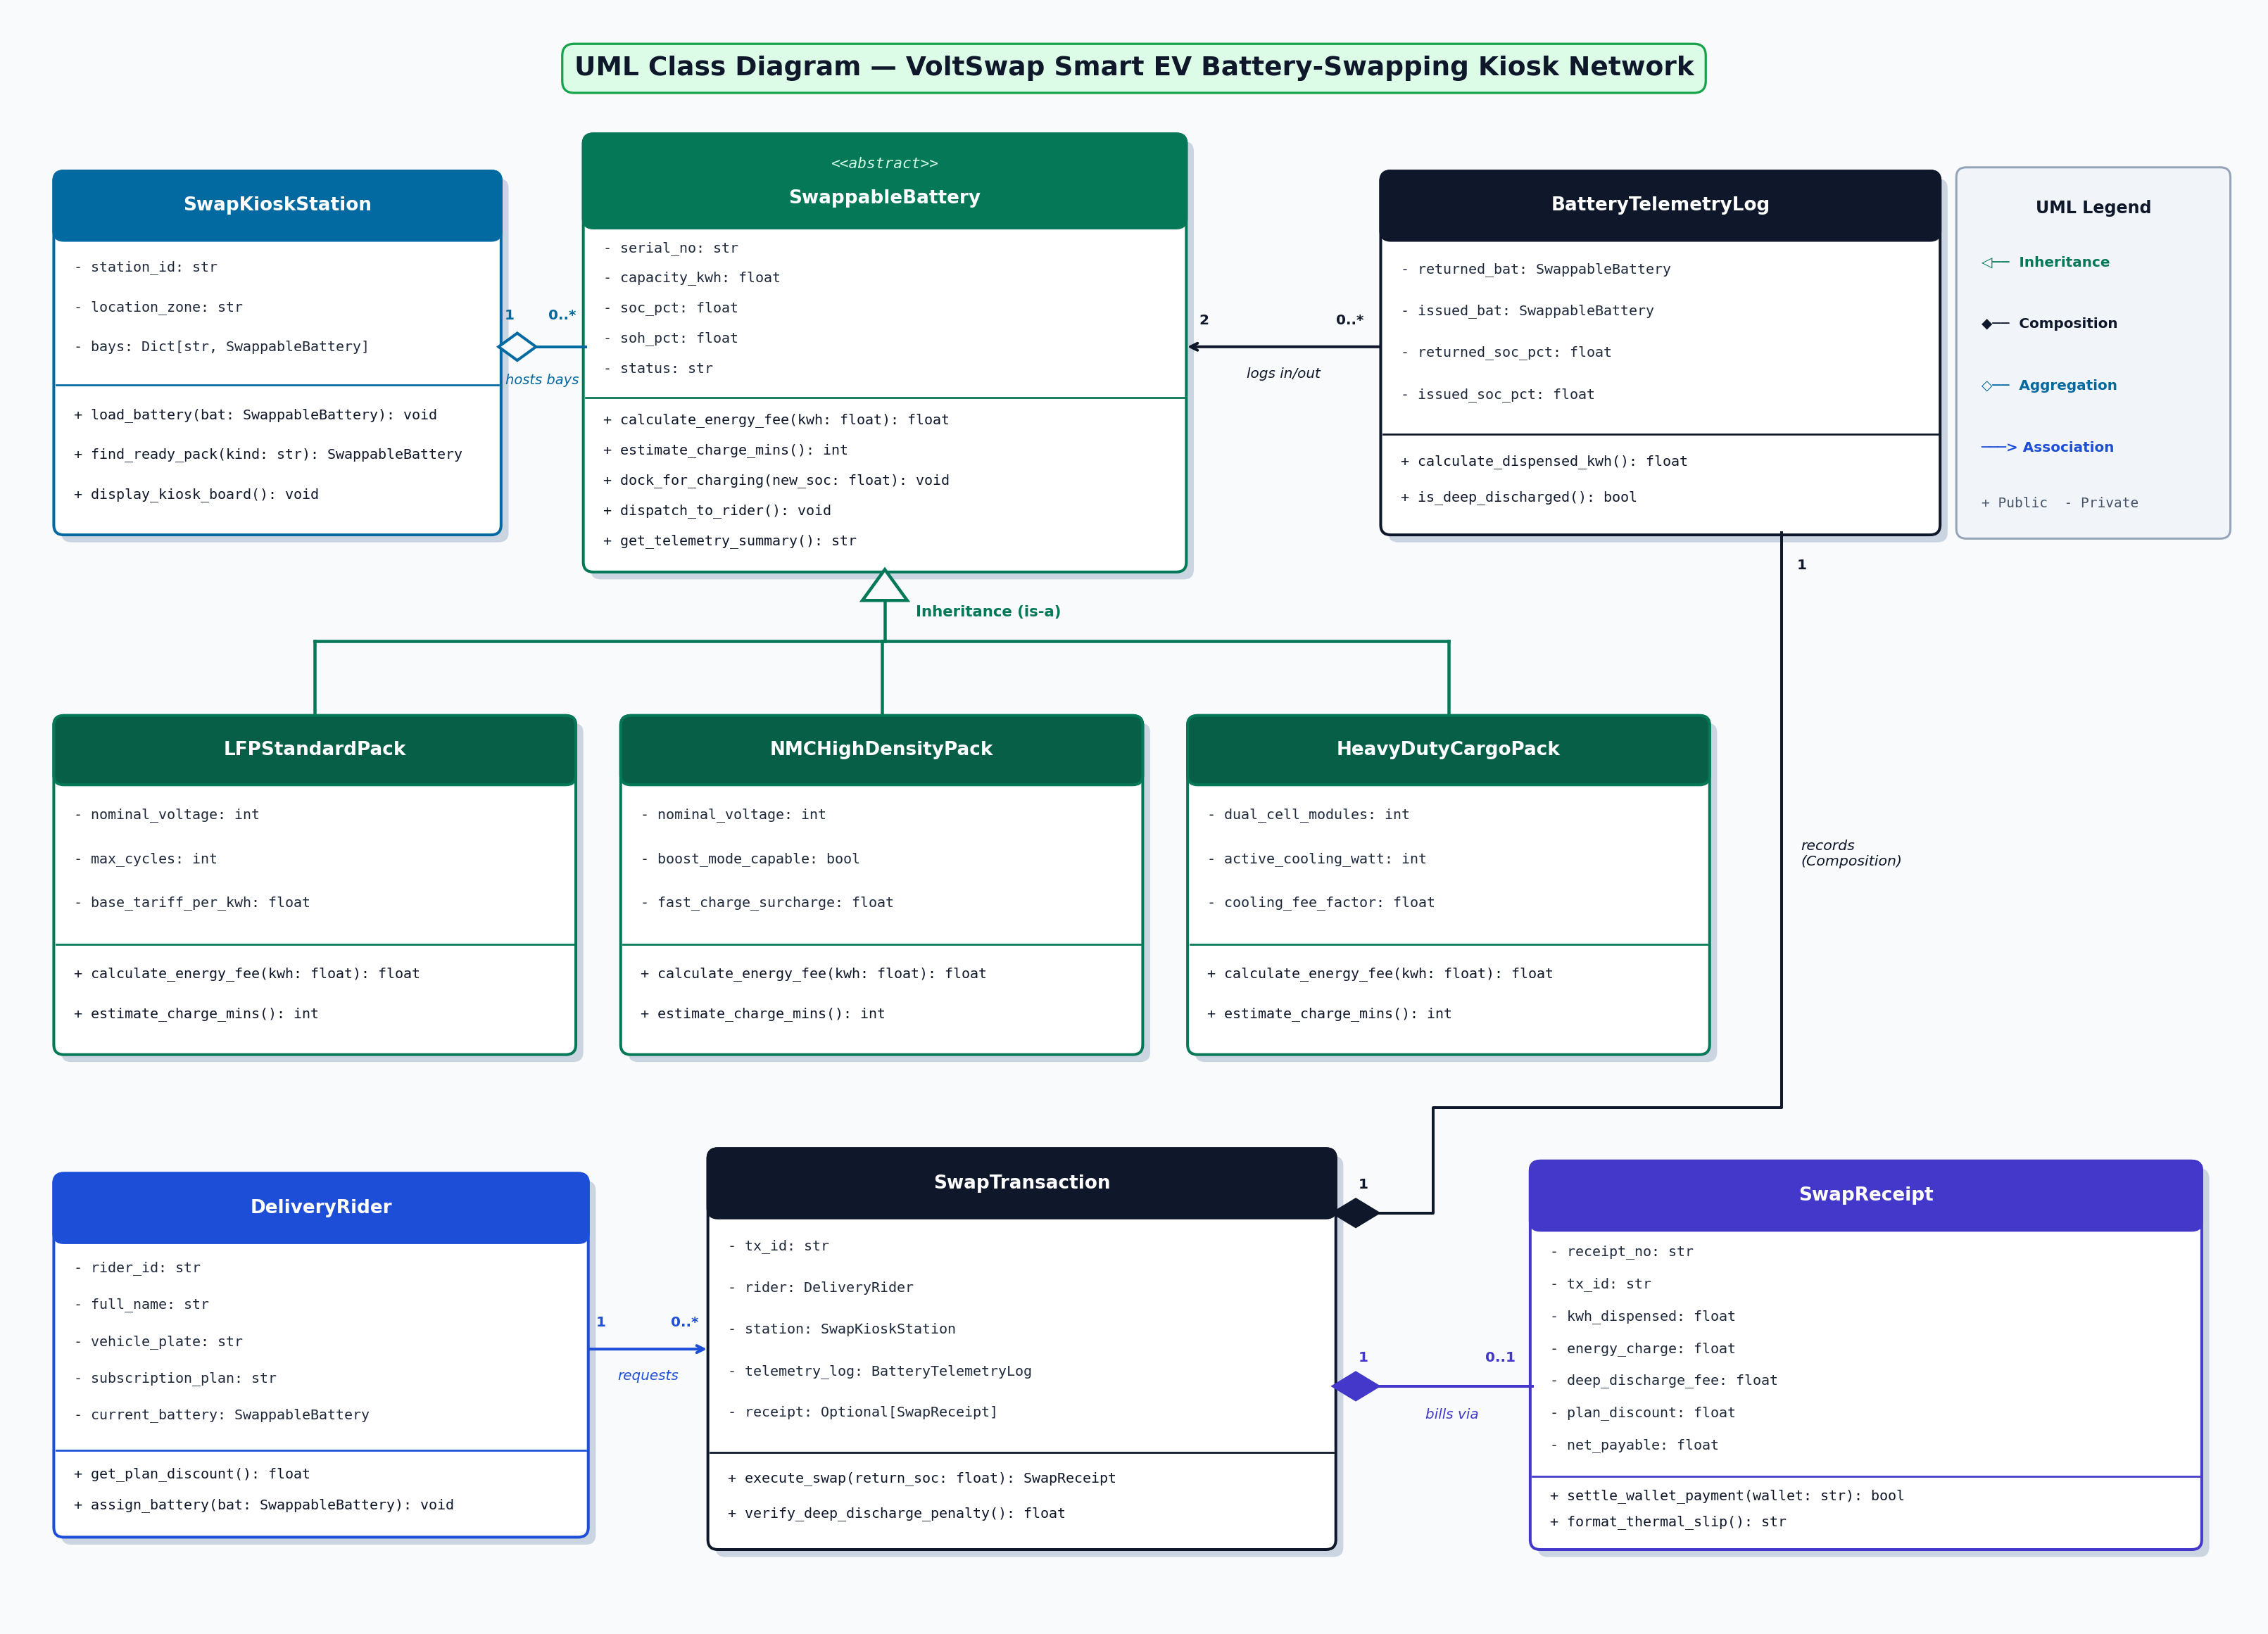

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def render_voltswap_class_diagram():
    fig, ax = plt.subplots(figsize=(18, 13), dpi=150)
    ax.set_xlim(0, 18)
    ax.set_ylim(0, 13)
    ax.axis('off')
    fig.patch.set_facecolor('#F8FAFC')

    ax.text(9, 12.55, "UML Class Diagram — VoltSwap Smart EV Battery-Swapping Kiosk Network",
            ha='center', va='center', fontsize=15, fontweight='bold', color='#0F172A',
            bbox=dict(boxstyle='round,pad=0.45', facecolor='#DCFCE7', edgecolor='#16A34A', lw=1.3))

    def draw_class_box(ax, x, y, w, h, title, stereotype, attrs, methods, header_bg='#065F46', body_bg='#FFFFFF', border_col='#065F46'):
        shadow = patches.FancyBboxPatch((x+0.06, y-0.06), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                        facecolor='#CBD5E1', edgecolor='none', zorder=1)
        ax.add_patch(shadow)
        main_box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                          facecolor=body_bg, edgecolor=border_col, linewidth=1.6, zorder=2)
        ax.add_patch(main_box)

        header_h = 0.72 if stereotype else 0.52
        header_box = patches.FancyBboxPatch((x, y + h - header_h), w, header_h,
                                            boxstyle="round,pad=0.02,rounding_size=0.08",
                                            facecolor=header_bg, edgecolor=border_col, linewidth=1.6, zorder=3)
        ax.add_patch(header_box)

        if stereotype:
            ax.text(x + w/2, y + h - 0.22, f"<<{stereotype}>>", ha='center', va='center',
                    fontsize=8.5, style='italic', color='#D1FAE5', zorder=4, family='monospace')
            ax.text(x + w/2, y + h - 0.50, title, ha='center', va='center',
                    fontsize=10.5, fontweight='bold', color='#FFFFFF', zorder=4)
        else:
            ax.text(x + w/2, y + h - 0.26, title, ha='center', va='center',
                    fontsize=10.5, fontweight='bold', color='#FFFFFF', zorder=4)

        content_h = h - header_h
        total_lines = max(len(attrs) + len(methods), 1)
        attr_ratio = max(len(attrs) / total_lines, 0.35)
        attr_h = content_h * attr_ratio
        div_y = y + content_h - attr_h
        ax.plot([x, x + w], [div_y, div_y], color=border_col, linewidth=1.1, zorder=4)

        if attrs:
            step = attr_h / (len(attrs) + 0.7)
            for idx, attr in enumerate(attrs):
                ay = (y + h - header_h) - (idx + 0.75) * step
                ax.text(x + 0.14, ay, attr, ha='left', va='center', fontsize=8.0,
                        color='#1E293B', family='monospace', zorder=4)

        method_h = div_y - y
        if methods:
            step = method_h / (len(methods) + 0.7)
            for idx, m in enumerate(methods):
                my = div_y - (idx + 0.75) * step
                ax.text(x + 0.14, my, m, ha='left', va='center', fontsize=8.0,
                        color='#0F172A', family='monospace', zorder=4)

    draw_class_box(ax, x=4.6, y=8.5, w=4.8, h=3.5, title="SwappableBattery", stereotype="abstract",
        attrs=["- serial_no: str", "- capacity_kwh: float", "- soc_pct: float", "- soh_pct: float", "- status: str"],
        methods=["+ calculate_energy_fee(kwh: float): float", "+ estimate_charge_mins(): int", "+ dock_for_charging(new_soc: float): void", "+ dispatch_to_rider(): void", "+ get_telemetry_summary(): str"],
        header_bg='#047857', border_col='#047857')

    draw_class_box(ax, x=0.35, y=4.6, w=4.15, h=2.7, title="LFPStandardPack", stereotype=None,
        attrs=["- nominal_voltage: int", "- max_cycles: int", "- base_tariff_per_kwh: float"],
        methods=["+ calculate_energy_fee(kwh: float): float", "+ estimate_charge_mins(): int"],
        header_bg='#065F46', border_col='#047857')

    draw_class_box(ax, x=4.9, y=4.6, w=4.15, h=2.7, title="NMCHighDensityPack", stereotype=None,
        attrs=["- nominal_voltage: int", "- boost_mode_capable: bool", "- fast_charge_surcharge: float"],
        methods=["+ calculate_energy_fee(kwh: float): float", "+ estimate_charge_mins(): int"],
        header_bg='#065F46', border_col='#047857')

    draw_class_box(ax, x=9.45, y=4.6, w=4.15, h=2.7, title="HeavyDutyCargoPack", stereotype=None,
        attrs=["- dual_cell_modules: int", "- active_cooling_watt: int", "- cooling_fee_factor: float"],
        methods=["+ calculate_energy_fee(kwh: float): float", "+ estimate_charge_mins(): int"],
        header_bg='#065F46', border_col='#047857')

    draw_class_box(ax, x=0.35, y=8.8, w=3.55, h=2.9, title="SwapKioskStation", stereotype=None,
        attrs=["- station_id: str", "- location_zone: str", "- bays: Dict[str, SwappableBattery]"],
        methods=["+ load_battery(bat: SwappableBattery): void", "+ find_ready_pack(kind: str): SwappableBattery", "+ display_kiosk_board(): void"],
        header_bg='#0369A1', border_col='#0369A1')

    draw_class_box(ax, x=0.35, y=0.7, w=4.25, h=2.9, title="DeliveryRider", stereotype=None,
        attrs=["- rider_id: str", "- full_name: str", "- vehicle_plate: str", "- subscription_plan: str", "- current_battery: SwappableBattery"],
        methods=["+ get_plan_discount(): float", "+ assign_battery(bat: SwappableBattery): void"],
        header_bg='#1D4ED8', border_col='#1D4ED8')

    draw_class_box(ax, x=5.6, y=0.6, w=5.0, h=3.2, title="SwapTransaction", stereotype=None,
        attrs=["- tx_id: str", "- rider: DeliveryRider", "- station: SwapKioskStation", "- telemetry_log: BatteryTelemetryLog", "- receipt: Optional[SwapReceipt]"],
        methods=["+ execute_swap(return_soc: float): SwapReceipt", "+ verify_deep_discharge_penalty(): float"],
        header_bg='#0F172A', border_col='#0F172A')

    draw_class_box(ax, x=11.0, y=8.8, w=4.45, h=2.9, title="BatteryTelemetryLog", stereotype=None,
        attrs=["- returned_bat: SwappableBattery", "- issued_bat: SwappableBattery", "- returned_soc_pct: float", "- issued_soc_pct: float"],
        methods=["+ calculate_dispensed_kwh(): float", "+ is_deep_discharged(): bool"],
        header_bg='#0F172A', border_col='#0F172A')

    draw_class_box(ax, x=12.2, y=0.6, w=5.35, h=3.1, title="SwapReceipt", stereotype=None,
        attrs=["- receipt_no: str", "- tx_id: str", "- kwh_dispensed: float", "- energy_charge: float", "- deep_discharge_fee: float", "- plan_discount: float", "- net_payable: float"],
        methods=["+ settle_wallet_payment(wallet: str): bool", "+ format_thermal_slip(): str"],
        header_bg='#4338CA', border_col='#4338CA')

    bus_y, c1_x, c2_x, c3_x, parent_x, parent_bottom = 7.92, 2.425, 6.975, 11.525, 7.0, 8.5
    ax.plot([c1_x, c1_x], [7.3, bus_y], color='#047857', lw=1.8)
    ax.plot([c2_x, c2_x], [7.3, bus_y], color='#047857', lw=1.8)
    ax.plot([c3_x, c3_x], [7.3, bus_y], color='#047857', lw=1.8)
    ax.plot([c1_x, c3_x], [bus_y, bus_y], color='#047857', lw=1.8)
    ax.plot([parent_x, parent_x], [bus_y, parent_bottom - 0.25], color='#047857', lw=1.8)
    ax.add_patch(patches.Polygon([[parent_x, parent_bottom], [parent_x - 0.18, parent_bottom - 0.25], [parent_x + 0.18, parent_bottom - 0.25]],
                                 closed=True, facecolor='#F8FAFC', edgecolor='#047857', lw=1.8, zorder=5))
    ax.text(parent_x + 0.25, 8.12, "Inheritance (is-a)", fontsize=8.5, fontweight='bold', color='#047857')

    ag_y = 10.3
    ax.add_patch(patches.Polygon([[3.90, ag_y], [4.05, ag_y+0.11], [4.20, ag_y], [4.05, ag_y-0.11]],
                                 closed=True, facecolor='#F8FAFC', edgecolor='#0369A1', lw=1.6, zorder=5))
    ax.plot([4.20, 4.60], [ag_y, ag_y], color='#0369A1', lw=1.6)
    ax.text(3.95, ag_y + 0.22, "1", fontsize=8, fontweight='bold', color='#0369A1')
    ax.text(4.30, ag_y + 0.22, "0..*", fontsize=8, fontweight='bold', color='#0369A1')
    ax.text(4.25, ag_y - 0.30, "hosts bays", ha='center', fontsize=7.8, style='italic', color='#0369A1')

    as_y = 10.3
    ax.annotate("", xy=(9.4, as_y), xytext=(11.0, as_y), arrowprops=dict(arrowstyle="->", color='#0F172A', lw=1.6))
    ax.text(10.62, as_y + 0.18, "0..*", fontsize=8, fontweight='bold', color='#0F172A')
    ax.text(9.52, as_y + 0.18, "2", fontsize=8, fontweight='bold', color='#0F172A')
    ax.text(10.20, as_y - 0.25, "logs in/out", ha='center', fontsize=8, style='italic', color='#0F172A')

    cl_y = 2.2
    ax.annotate("", xy=(5.6, cl_y), xytext=(4.6, cl_y), arrowprops=dict(arrowstyle="->", color='#1D4ED8', lw=1.6))
    ax.text(4.68, cl_y + 0.18, "1", fontsize=8, fontweight='bold', color='#1D4ED8')
    ax.text(5.28, cl_y + 0.18, "0..*", fontsize=8, fontweight='bold', color='#1D4ED8')
    ax.text(5.1, cl_y - 0.25, "requests", ha='center', fontsize=8, style='italic', color='#1D4ED8')

    comp1_y = 3.3
    ax.add_patch(patches.Polygon([[10.6, comp1_y], [10.78, comp1_y+0.11], [10.96, comp1_y], [10.78, comp1_y-0.11]],
                                 closed=True, facecolor='#0F172A', edgecolor='#0F172A', lw=1.6, zorder=5))
    ax.plot([10.96, 11.4, 11.4, 14.2, 14.2], [comp1_y, comp1_y, 4.15, 4.15, 8.8], color='#0F172A', lw=1.6)
    ax.text(10.8, comp1_y + 0.20, "1", fontsize=8, fontweight='bold', color='#0F172A')
    ax.text(14.32, 8.5, "1", fontsize=8, fontweight='bold', color='#0F172A')
    ax.text(14.35, 6.2, "records\n(Composition)", ha='left', va='center', fontsize=8.2, style='italic', color='#0F172A')

    comp2_y = 1.9
    ax.add_patch(patches.Polygon([[10.6, comp2_y], [10.78, comp2_y+0.11], [10.96, comp2_y], [10.78, comp2_y-0.11]],
                                 closed=True, facecolor='#4338CA', edgecolor='#4338CA', lw=1.6, zorder=5))
    ax.plot([10.96, 12.2], [comp2_y, comp2_y], color='#4338CA', lw=1.6)
    ax.text(10.8, comp2_y + 0.20, "1", fontsize=8, fontweight='bold', color='#4338CA')
    ax.text(11.82, comp2_y + 0.20, "0..1", fontsize=8, fontweight='bold', color='#4338CA')
    ax.text(11.55, comp2_y - 0.26, "bills via", ha='center', fontsize=8, style='italic', color='#4338CA')

    leg_box = patches.FancyBboxPatch((15.65, 8.8), 2.1, 2.9, boxstyle="round,pad=0.05,rounding_size=0.08",
                                     facecolor='#F1F5F9', edgecolor='#94A3B8', lw=1.2)
    ax.add_patch(leg_box)
    ax.text(16.7, 11.42, "UML Legend", ha='center', va='center', fontsize=9.5, fontweight='bold', color='#0F172A')
    ax.text(15.8, 10.95, "◁──  Inheritance", fontsize=8, color='#047857', fontweight='bold')
    ax.text(15.8, 10.45, "◆──  Composition", fontsize=8, color='#0F172A', fontweight='bold')
    ax.text(15.8, 9.95,  "◇──  Aggregation", fontsize=8, color='#0369A1', fontweight='bold')
    ax.text(15.8, 9.45,  "───> Association", fontsize=8, color='#1D4ED8', fontweight='bold')
    ax.text(15.8, 9.00,  "+ Public  - Private", fontsize=7.8, color='#475569', family='monospace')

    plt.tight_layout()
    plt.show()

render_voltswap_class_diagram()

## 3. UML Sequence Diagram

### 3.1 Scenario Description: 60-Second Smart Battery Swap & Telemetry Billing
This sequence diagram traces the real-time object interactions when a `DeliveryRider` arrives at a `SwapKioskStation` with a depleted battery (`14.0%` SoC):
1. **Swap Request (`execute_swap`):** The `DeliveryRider` initiates `execute_swap(return_soc=14.0%)` on `SwapTransaction`.
2. **Compatible Pack Lookup (`find_ready_pack`):** `SwapTransaction` queries `SwapKioskStation` for a `100% READY` battery matching the rider's exact pack class (`NMCHighDensityPack`).
3. **Atomic Bay Transition (`dock_for_charging` & `dispatch_to_rider`):** The rider's depleted battery is locked into a kiosk charging slot (`status = CHARGING`, `soc_pct = 14.0%`) and the newly selected battery is released (`status = IN_VEHICLE`).
4. **Telemetry & Polymorphic Tariff Calculation:** `SwapTransaction` instantiates `BatteryTelemetryLog` to compute exact `dispensed_kwh` and check `is_deep_discharged()`, then invokes the polymorphic `calculate_energy_fee(dispensed_kwh)` on the battery subclass.
5. **Discount & Receipt Generation:** `SwapTransaction` retrieves the rider's subscription discount (`get_plan_discount()`), updates the rider's active battery (`assign_battery()`), and creates `SwapReceipt`.
6. **Digital Wallet Settlement:** The rider settles the receipt via digital wallet (`InstaPay / RiderWallet`) and receives a formatted thermal slip.

### 3.2 Mermaid Sequence Diagram Specification
```mermaid
sequenceDiagram
    autonumber
    participant R as r : DeliveryRider
    participant TX as tx : SwapTransaction
    participant ST as st : SwapKioskStation
    participant BAT as bat : SwappableBattery
    participant LOG as log : BatteryTelemetryLog
    participant RC as rc : SwapReceipt

    R->>TX: execute_swap(return_soc=14.0%)
    TX->>ST: find_ready_pack(pack_type)
    ST-->>TX: issued_bat (100% READY)

    rect rgb(220, 252, 231)
        Note over TX,LOG: Critical Section: Atomic Bay Lock, Telemetry & Polymorphic Tariff
        TX->>BAT: dock_for_charging(14.0%) & dispatch_to_rider()
        TX->>LOG: <<create>> BatteryTelemetryLog(old_bat, new_bat)
        LOG-->>TX: dispensed_kwh & is_deep_discharged()
        TX->>BAT: calculate_energy_fee(dispensed_kwh) [Polymorphic]
        BAT-->>TX: energy_charge
    end

    TX->>R: get_plan_discount() & assign_battery(issued_bat)
    TX->>RC: <<create>> SwapReceipt(kwh, energy_charge, penalty, discount)
    RC-->>TX: receipt
    R->>RC: settle_wallet_payment("InstaPay / RiderWallet")
    RC-->>R: format_thermal_slip() [SWAP COMPLETED IN 48s]
```

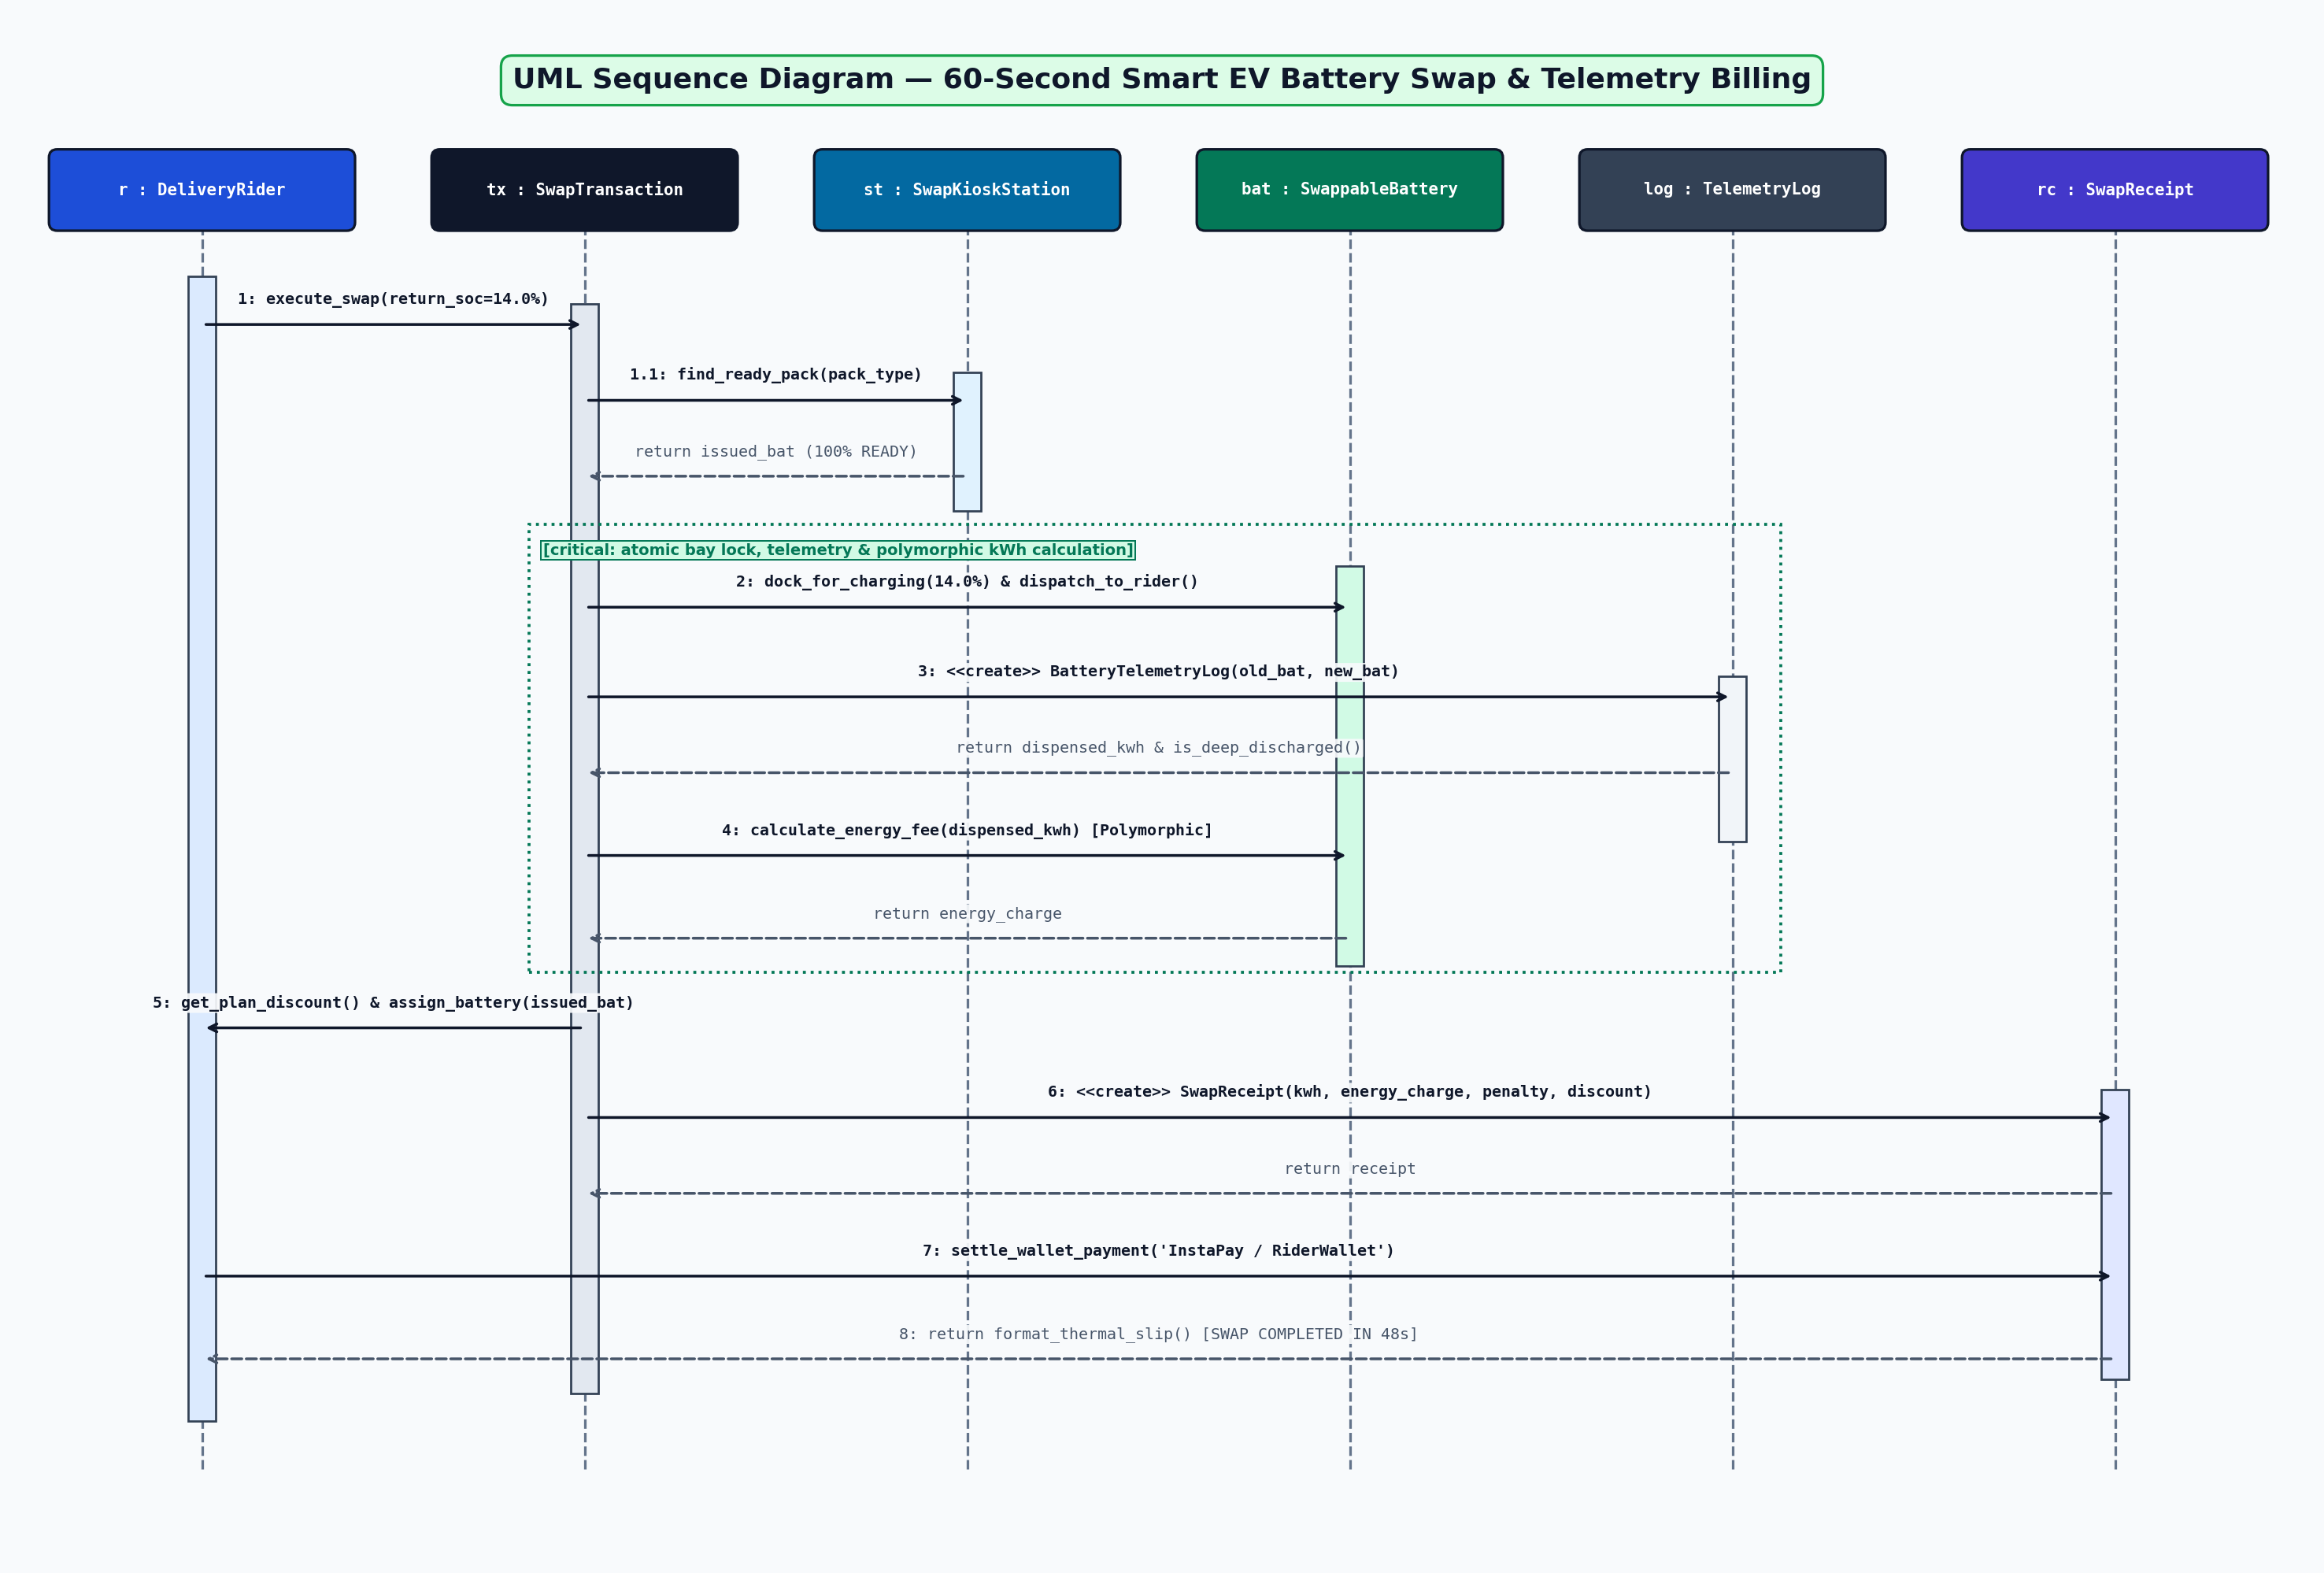

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def render_voltswap_sequence_diagram():
    fig, ax = plt.subplots(figsize=(16.5, 11.2), dpi=150)
    ax.set_xlim(0, 16.5)
    ax.set_ylim(0, 11.2)
    ax.axis('off')
    fig.patch.set_facecolor('#F8FAFC')

    ax.text(8.25, 10.72, "UML Sequence Diagram — 60-Second Smart EV Battery Swap & Telemetry Billing",
            ha='center', va='center', fontsize=14.5, fontweight='bold', color='#0F172A',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#DCFCE7', edgecolor='#16A34A', lw=1.3))

    participants = [
        ("r : DeliveryRider", 1.35, "#1D4ED8"),
        ("tx : SwapTransaction", 4.10, "#0F172A"),
        ("st : SwapKioskStation", 6.85, "#0369A1"),
        ("bat : SwappableBattery", 9.60, "#047857"),
        ("log : TelemetryLog", 12.35, "#334155"),
        ("rc : SwapReceipt", 15.10, "#4338CA")
    ]

    top_y, bottom_y = 9.65, 0.65
    for label, x, col in participants:
        box = patches.FancyBboxPatch((x - 1.08, top_y), 2.16, 0.55,
                                     boxstyle="round,pad=0.02,rounding_size=0.06",
                                     facecolor=col, edgecolor='#0F172A', lw=1.3, zorder=3)
        ax.add_patch(box)
        ax.text(x, top_y + 0.275, label, ha='center', va='center',
                fontsize=8.3, fontweight='bold', color='#FFFFFF', family='monospace', zorder=4)
        ax.plot([x, x], [bottom_y, top_y], color='#64748B', linestyle='--', linewidth=1.3, zorder=1)

    def draw_activation(x, y_start, y_end, col='#CBD5E1'):
        ax.add_patch(patches.Rectangle((x - 0.10, y_end), 0.20, y_start - y_end,
                                       facecolor=col, edgecolor='#334155', lw=1.1, zorder=2))

    draw_activation(1.35, 9.3, 1.0, '#DBEAFE')
    draw_activation(4.10, 9.1, 1.2, '#E2E8F0')
    draw_activation(6.85, 8.6, 7.6, '#E0F2FE')
    draw_activation(9.60, 7.2, 4.3, '#D1FAE5')
    draw_activation(12.35, 6.4, 5.2, '#F1F5F9')
    draw_activation(15.10, 3.4, 1.3, '#E0E7FF')

    def draw_msg(x1, x2, y, text, is_return=False):
        ls = '--' if is_return else '-'
        col = '#475569' if is_return else '#0F172A'
        ax.annotate("", xy=(x2, y), xytext=(x1, y),
                    arrowprops=dict(arrowstyle="->", color=col, lw=1.4, linestyle=ls), zorder=4)
        ax.text((x1 + x2) / 2, y + 0.12, text, ha='center', va='bottom', fontsize=8.0,
                fontweight='bold' if not is_return else 'normal', color=col, family='monospace',
                bbox=dict(boxstyle='round,pad=0.10', facecolor='#F8FAFC', edgecolor='none', alpha=0.92), zorder=5)

    draw_msg(1.35, 4.10, 8.95, "1: execute_swap(return_soc=14.0%)")
    draw_msg(4.10, 6.85, 8.40, "1.1: find_ready_pack(pack_type)")
    draw_msg(6.85, 4.10, 7.85, "return issued_bat (100% READY)", is_return=True)

    frame_box = patches.Rectangle((3.70, 4.25), 9.0, 3.25, fill=False, edgecolor='#047857', linestyle=':', lw=1.5, zorder=3)
    ax.add_patch(frame_box)
    ax.text(3.80, 7.28, "[critical: atomic bay lock, telemetry & polymorphic kWh calculation]",
            fontsize=7.8, fontweight='bold', color='#047857',
            bbox=dict(boxstyle='square,pad=0.12', facecolor='#D1FAE5', edgecolor='#047857', lw=0.8), zorder=6)

    draw_msg(4.10, 9.60, 6.90, "2: dock_for_charging(14.0%) & dispatch_to_rider()")
    draw_msg(4.10, 12.35, 6.25, "3: <<create>> BatteryTelemetryLog(old_bat, new_bat)")
    draw_msg(12.35, 4.10, 5.70, "return dispensed_kwh & is_deep_discharged()", is_return=True)
    draw_msg(4.10, 9.60, 5.10, "4: calculate_energy_fee(dispensed_kwh) [Polymorphic]")
    draw_msg(9.60, 4.10, 4.50, "return energy_charge", is_return=True)

    draw_msg(4.10, 1.35, 3.85, "5: get_plan_discount() & assign_battery(issued_bat)")
    draw_msg(4.10, 15.10, 3.20, "6: <<create>> SwapReceipt(kwh, energy_charge, penalty, discount)")
    draw_msg(15.10, 4.10, 2.65, "return receipt", is_return=True)
    draw_msg(1.35, 15.10, 2.05, "7: settle_wallet_payment('InstaPay / RiderWallet')")
    draw_msg(15.10, 1.35, 1.45, "8: return format_thermal_slip() [SWAP COMPLETED IN 48s]", is_return=True)

    plt.tight_layout()
    plt.show()

render_voltswap_sequence_diagram()

## 4. Python Implementation & Example Usage

### 4.1 Complete Object-Oriented Class Implementation
The code cell below implements all 8 classes from the UML Class Diagram (`SwappableBattery`, `LFPStandardPack`, `NMCHighDensityPack`, `HeavyDutyCargoPack`, `SwapKioskStation`, `DeliveryRider`, `BatteryTelemetryLog`, `SwapReceipt`, and `SwapTransaction`).

In [ ]:
from abc import ABC, abstractmethod
from typing import Dict, Optional, List


# =====================================================================
# 1. ABSTRACT BASE CLASS & SUBCLASSES (INHERITANCE & POLYMORPHISM)
# =====================================================================

class SwappableBattery(ABC):
    """
    Abstract base class representing a smart lithium battery module in the VoltSwap network.
    Demonstrates Abstraction, Encapsulation, and Polymorphism.
    """
    def __init__(self, serial_no: str, capacity_kwh: float, soc_pct: float = 100.0,
                 soh_pct: float = 99.0, status: str = "READY"):
        self._serial_no: str = serial_no
        self._capacity_kwh: float = capacity_kwh
        self._soc_pct: float = soc_pct       # State of Charge (0.0% to 100.0%)
        self._soh_pct: float = soh_pct       # State of Health (0.0% to 100.0%)
        self._status: str = status           # "READY", "CHARGING", "IN_VEHICLE"

    @property
    def serial_no(self) -> str:
        return self._serial_no

    @property
    def capacity_kwh(self) -> float:
        return self._capacity_kwh

    @property
    def soc_pct(self) -> float:
        return self._soc_pct

    @property
    def status(self) -> str:
        return self._status

    @property
    def pack_category(self) -> str:
        return self.__class__.__name__

    def dock_for_charging(self, returned_soc_pct: float) -> None:
        """Locks a depleted battery into a kiosk charging bay and updates its telemetry."""
        if not (0.0 <= returned_soc_pct <= 100.0):
            raise ValueError("State of Charge (SoC) must be between 0% and 100%.")
        self._soc_pct = returned_soc_pct
        self._status = "CHARGING"

    def dispatch_to_rider(self) -> None:
        """Releases a fully charged battery from the kiosk to a delivery rider's vehicle."""
        if self._status != "READY" or self._soc_pct < 95.0:
            raise RuntimeError(f"Battery {self._serial_no} is not ready for dispatch (Status: {self._status}, SoC: {self._soc_pct}%).")
        self._status = "IN_VEHICLE"

    @abstractmethod
    def calculate_energy_fee(self, dispensed_kwh: float) -> float:
        """
        Polymorphic method: Each battery chemistry & form-factor calculates its
        energy and cell-wear tariff differently per dispensed kWh.
        """
        pass

    @abstractmethod
    def estimate_charge_mins(self) -> int:
        """Polymorphic method: Estimates minutes remaining until 100% charge."""
        pass

    def get_telemetry_summary(self) -> str:
        return (f"[{self.pack_category:<18} | {self._serial_no}] "
                f"Cap: {self._capacity_kwh:.1f} kWh | SoC: {self._soc_pct:>5.1f}% | "
                f"SoH: {self._soh_pct:>4.1f}% | Status: {self._status:<10} "
                f"(Est. Charge: {self.estimate_charge_mins()} min)")


class LFPStandardPack(SwappableBattery):
    """
    Subclass 1: Lithium Iron Phosphate (LFP) pack for standard urban E-Scooters.
    High cycle life, lowest per-kWh tariff, standard charging speed.
    """
    def __init__(self, serial_no: str, capacity_kwh: float = 2.0, soc_pct: float = 100.0,
                 nominal_voltage: int = 48, max_cycles: int = 3500, base_tariff_per_kwh: float = 8.50):
        super().__init__(serial_no, capacity_kwh, soc_pct)
        self._nominal_voltage: int = nominal_voltage
        self._max_cycles: int = max_cycles
        self._base_tariff_per_kwh: float = base_tariff_per_kwh  # EGP per kWh

    def calculate_energy_fee(self, dispensed_kwh: float) -> float:
        return round(dispensed_kwh * self._base_tariff_per_kwh, 2)

    def estimate_charge_mins(self) -> int:
        if self._soc_pct >= 100.0:
            return 0
        missing_pct = 100.0 - self._soc_pct
        return int(round(missing_pct * 0.65))  # ~65 mins from 0% to 100%


class NMCHighDensityPack(SwappableBattery):
    """
    Subclass 2: Nickel Manganese Cobalt (NMC) high-density pack for fast delivery E-Motorcycles.
    Higher energy density & ultra-fast charging with a fast-charge cell balancing surcharge.
    """
    def __init__(self, serial_no: str, capacity_kwh: float = 3.5, soc_pct: float = 100.0,
                 nominal_voltage: int = 72, boost_mode_capable: bool = True, fast_charge_surcharge: float = 12.00):
        super().__init__(serial_no, capacity_kwh, soc_pct)
        self._nominal_voltage: int = nominal_voltage
        self._boost_mode_capable: bool = boost_mode_capable
        self._fast_charge_surcharge: float = fast_charge_surcharge  # EGP flat fast-charge balancing fee

    def calculate_energy_fee(self, dispensed_kwh: float) -> float:
        # 10.50 EGP per kWh + flat fast-charge cell balancing fee
        return round((dispensed_kwh * 10.50) + self._fast_charge_surcharge, 2)

    def estimate_charge_mins(self) -> int:
        if self._soc_pct >= 100.0:
            return 0
        missing_pct = 100.0 - self._soc_pct
        return int(round(missing_pct * 0.42))  # Ultra-fast ~42 mins from 0% to 100%


class HeavyDutyCargoPack(SwappableBattery):
    """
    Subclass 3: Dual-module high-capacity pack for three-wheel electric cargo Tuk-Tuks / trikes.
    Includes active liquid/air thermal management cooling factor.
    """
    def __init__(self, serial_no: str, capacity_kwh: float = 5.5, soc_pct: float = 100.0,
                 dual_cell_modules: int = 2, active_cooling_watt: int = 180, cooling_fee_factor: float = 1.15):
        super().__init__(serial_no, capacity_kwh, soc_pct)
        self._dual_cell_modules: int = dual_cell_modules
        self._active_cooling_watt: int = active_cooling_watt
        self._cooling_fee_factor: float = cooling_fee_factor

    def calculate_energy_fee(self, dispensed_kwh: float) -> float:
        # 11.00 EGP per kWh multiplied by the active thermal cooling factor (1.15x)
        return round(dispensed_kwh * 11.00 * self._cooling_fee_factor, 2)

    def estimate_charge_mins(self) -> int:
        if self._soc_pct >= 100.0:
            return 0
        missing_pct = 100.0 - self._soc_pct
        return int(round(missing_pct * 0.80))


# =====================================================================
# 2. SWAP KIOSK STATION CLASS (AGGREGATION: o--)
# =====================================================================

class SwapKioskStation:
    """
    Aggregates SwappableBattery modules across smart charging bays.
    Batteries move between kiosks and vehicles independently of any single kiosk.
    """
    def __init__(self, station_id: str, location_zone: str):
        self._station_id: str = station_id
        self._location_zone: str = location_zone
        self._bays: Dict[str, SwappableBattery] = {}

    @property
    def station_id(self) -> str:
        return self._station_id

    @property
    def location_zone(self) -> str:
        return self._location_zone

    def load_battery(self, battery: SwappableBattery) -> None:
        self._bays[battery.serial_no] = battery

    def find_ready_pack(self, kind: str) -> SwappableBattery:
        """Finds a 100% READY battery matching the rider's required battery class name."""
        for bat in self._bays.values():
            if bat.pack_category == kind and bat.status == "READY" and bat.soc_pct >= 95.0:
                return bat
        raise LookupError(f"No READY '{kind}' battery currently available at {self._location_zone} ({self._station_id}).")

    def display_kiosk_board(self) -> None:
        ready_count = sum(1 for b in self._bays.values() if b.status == "READY")
        print(f"\n{'='*94}")
        print(f"  VOLTSWAP KIOSK [{self._station_id}] — {self._location_zone.upper()} ({ready_count}/{len(self._bays)} Bays Ready for Instant Swap)")
        print(f"{'='*94}")
        for bat in self._bays.values():
            print("  " + bat.get_telemetry_summary())
        print(f"{'='*94}")


# =====================================================================
# 3. DELIVERY RIDER CLASS (ASSOCIATION: -->)
# =====================================================================

class DeliveryRider:
    """Represents an e-mobility courier or delivery rider registered on VoltSwap."""
    PLAN_DISCOUNTS = {
        "PayAsYouGo": 0.00,
        "ProRider": 0.15,        # 15% discount on energy fees for full-time couriers
        "FleetUnlimited": 0.25   # 25% discount for corporate delivery fleets
    }

    def __init__(self, rider_id: str, full_name: str, vehicle_plate: str,
                 subscription_plan: str, current_battery: SwappableBattery):
        if subscription_plan not in self.PLAN_DISCOUNTS:
            raise ValueError(f"Unknown plan: {subscription_plan}")
        self._rider_id: str = rider_id
        self._full_name: str = full_name
        self._vehicle_plate: str = vehicle_plate
        self._subscription_plan: str = subscription_plan
        self._current_battery: SwappableBattery = current_battery
        # Mark the rider's initial battery as mounted in their vehicle
        self._current_battery._status = "IN_VEHICLE"

    @property
    def full_name(self) -> str:
        return self._full_name

    @property
    def subscription_plan(self) -> str:
        return self._subscription_plan

    @property
    def current_battery(self) -> SwappableBattery:
        return self._current_battery

    def get_plan_discount(self) -> float:
        return self.PLAN_DISCOUNTS[self._subscription_plan]

    def assign_battery(self, new_battery: SwappableBattery) -> None:
        self._current_battery = new_battery


# =====================================================================
# 4. TELEMETRY LOG & SWAP RECEIPT (COMPOSITION: *--)
# =====================================================================

class BatteryTelemetryLog:
    """
    Composed inside a SwapTransaction. Captures exact State-of-Charge (SoC) delta
    between the returned depleted battery and the newly issued charged battery.
    """
    DEEP_DISCHARGE_THRESHOLD_PCT = 10.0  # Returning below 10% harms lithium cells

    def __init__(self, returned_bat: SwappableBattery, issued_bat: SwappableBattery,
                 returned_soc_pct: float, issued_soc_pct: float):
        self._returned_bat: SwappableBattery = returned_bat
        self._issued_bat: SwappableBattery = issued_bat
        self._returned_soc_pct: float = returned_soc_pct
        self._issued_soc_pct: float = issued_soc_pct

    def calculate_dispensed_kwh(self) -> float:
        """Calculates net energy (kWh) transferred to the rider during the swap."""
        soc_delta_fraction = max(0.0, (self._issued_soc_pct - self._returned_soc_pct) / 100.0)
        return round(self._issued_bat.capacity_kwh * soc_delta_fraction, 2)

    def is_deep_discharged(self) -> bool:
        """Returns True if the rider drained the battery below the safe 10% threshold."""
        return self._returned_soc_pct < self.DEEP_DISCHARGE_THRESHOLD_PCT


class SwapReceipt:
    """
    Composed inside a SwapTransaction. Computes final rider billing and generates
    a formatted smart-kiosk thermal slip.
    """
    def __init__(self, receipt_no: str, tx_id: str, rider_name: str, plan_name: str,
                 station_zone: str, old_serial: str, new_serial: str,
                 returned_soc: float, issued_soc: float, kwh_dispensed: float,
                 energy_charge: float, deep_discharge_fee: float, plan_discount: float):
        self._receipt_no: str = receipt_no
        self._tx_id: str = tx_id
        self._rider_name: str = rider_name
        self._plan_name: str = plan_name
        self._station_zone: str = station_zone
        self._old_serial: str = old_serial
        self._new_serial: str = new_serial
        self._returned_soc: float = returned_soc
        self._issued_soc: float = issued_soc
        self._kwh_dispensed: float = kwh_dispensed
        self._energy_charge: float = energy_charge
        self._deep_discharge_fee: float = deep_discharge_fee
        self._plan_discount: float = plan_discount
        self._net_payable: float = round((energy_charge - plan_discount) + deep_discharge_fee, 2)
        self._paid_via: Optional[str] = None

    def settle_wallet_payment(self, wallet_provider: str) -> bool:
        self._paid_via = wallet_provider
        return True

    def format_thermal_slip(self) -> str:
        payment_status = f"PAID ({self._paid_via})" if self._paid_via else "PENDING"
        rows = [
            f"\n+{'-'*64}+",
            f"| {'VOLTSWAP 60-SECOND SMART BATTERY SWAP RECEIPT':^62} |",
            f"+{'-'*64}+",
            f"| Receipt / TX ID   : {f'{self._receipt_no} / {self._tx_id}':<42} |",
            f"| Kiosk Location    : {self._station_zone:<42} |",
            f"| Rider & Plan      : {f'{self._rider_name} ({self._plan_name})':<42} |",
            f"| Battery Docked IN : {f'{self._old_serial} (Returned at {self._returned_soc:.1f}% SoC)':<42} |",
            f"| Battery Issued OUT: {f'{self._new_serial} (Issued at {self._issued_soc:.1f}% SoC)':<42} |",
            f"| Net Energy Added  : {f'{self._kwh_dispensed:.2f} kWh':<42} |",
            f"+{'-'*64}+",
            f"| Polymorphic Energy Tariff       : {self._energy_charge:>24.2f} EGP |",
            f"| Subscription Plan Discount      : -{self._plan_discount:>23.2f} EGP |",
            f"| Deep-Discharge Cell Penalty     : {self._deep_discharge_fee:>24.2f} EGP |",
            f"+{'-'*64}+",
            f"| NET TOTAL DEDUCTED ({payment_status:<11}) : {self._net_payable:>24.2f} EGP |",
            f"+{'-'*64}+"
        ]
        return "\n".join(rows)


# =====================================================================
# 5. SWAP TRANSACTION CLASS (CORE ORCHESTRATOR)
# =====================================================================

class SwapTransaction:
    """
    Orchestrates the physical and financial swap between a DeliveryRider and a SwapKioskStation.
    Composes BatteryTelemetryLog (1) and SwapReceipt (0..1).
    """
    DEEP_DISCHARGE_PENALTY_EGP = 25.00

    def __init__(self, tx_id: str, rider: DeliveryRider, station: SwapKioskStation):
        self._tx_id: str = tx_id
        self._rider: DeliveryRider = rider
        self._station: SwapKioskStation = station
        self._telemetry_log: Optional[BatteryTelemetryLog] = None
        self._receipt: Optional[SwapReceipt] = None

    def verify_deep_discharge_penalty(self) -> float:
        if self._telemetry_log and self._telemetry_log.is_deep_discharged():
            return self.DEEP_DISCHARGE_PENALTY_EGP
        return 0.0

    def execute_swap(self, return_soc_pct: float) -> SwapReceipt:
        old_bat = self._rider.current_battery
        required_kind = old_bat.pack_category

        # 1. Locate a compatible 100% READY battery in the kiosk
        new_bat = self._station.find_ready_pack(required_kind)
        issued_soc = new_bat.soc_pct

        # 2. Dock the rider's depleted battery into the kiosk & release the new battery
        old_bat.dock_for_charging(return_soc_pct)
        self._station.load_battery(old_bat)
        new_bat.dispatch_to_rider()

        # 3. Create Composed BatteryTelemetryLog
        self._telemetry_log = BatteryTelemetryLog(
            returned_bat=old_bat,
            issued_bat=new_bat,
            returned_soc_pct=return_soc_pct,
            issued_soc_pct=issued_soc
        )
        dispensed_kwh = self._telemetry_log.calculate_dispensed_kwh()

        # 4. Compute Polymorphic Energy Fee, Plan Discount, and Deep-Discharge Penalty
        energy_charge = new_bat.calculate_energy_fee(dispensed_kwh)
        discount = round(energy_charge * self._rider.get_plan_discount(), 2)
        penalty = self.verify_deep_discharge_penalty()

        # 5. Assign the new battery to the rider's vehicle
        self._rider.assign_battery(new_bat)

        # 6. Create Composed SwapReceipt
        receipt_no = f"RCP-{self._tx_id.split('-')[-1]}"
        self._receipt = SwapReceipt(
            receipt_no=receipt_no,
            tx_id=self._tx_id,
            rider_name=self._rider.full_name,
            plan_name=self._rider.subscription_plan,
            station_zone=f"{self._station.location_zone} ({self._station.station_id})",
            old_serial=old_bat.serial_no,
            new_serial=new_bat.serial_no,
            returned_soc=return_soc_pct,
            issued_soc=issued_soc,
            kwh_dispensed=dispensed_kwh,
            energy_charge=energy_charge,
            deep_discharge_fee=penalty,
            plan_discount=discount
        )
        return self._receipt

print("All 8 VoltSwap OOP classes loaded successfully.")


All 8 VoltSwap OOP classes loaded successfully.


### 4.2 End-to-End Multi-Scenario Simulation & Output Verification
The simulation cell below demonstrates three realistic operational scenarios at the **Maadi Degla Hub (`KSK-CAI-09`)** kiosk:
* **Scenario A (Normal ProRider Swap):** Fast delivery motorcycle rider swaps an `NMCHighDensityPack` drained to `14.0%` SoC for a `100%` charged pack, receiving `3.01 kWh` of energy with a `15%` ProRider discount and `0 EGP` penalty.
* **Scenario B (Deep-Discharge Cargo Swap):** Cargo tricycle rider swaps a `HeavyDutyCargoPack` drained to `6.0%` SoC (below the `10%` cell-safety threshold), triggering the automatic `25.00 EGP` deep-discharge cell protection penalty alongside polymorphic active-cooling tariff calculation.
* **Scenario C (Kiosk Safeguard Test):** A second NMC motorcycle rider attempts to swap at the same kiosk while the returned NMC pack is still in `CHARGING` status (`14.0%` SoC, `36 min` remaining), verifying that the kiosk blocks dispatching uncharged batteries.

In [ ]:
# =====================================================================
# STEP 1: Initialize Smart Kiosk Station in Maadi & Load Battery Bays
# =====================================================================
maadi_kiosk = SwapKioskStation(station_id="KSK-CAI-09", location_zone="Maadi Degla Hub")

# Create batteries across all 3 polymorphic subclasses
bat_lfp_ready = LFPStandardPack(serial_no="LFP-48V-101", capacity_kwh=2.0, soc_pct=100.0)
bat_nmc_ready = NMCHighDensityPack(serial_no="NMC-72V-201", capacity_kwh=3.5, soc_pct=100.0)
bat_cargo_ready = HeavyDutyCargoPack(serial_no="CRG-96V-301", capacity_kwh=5.5, soc_pct=100.0)

for b in [bat_lfp_ready, bat_nmc_ready, bat_cargo_ready]:
    maadi_kiosk.load_battery(b)

maadi_kiosk.display_kiosk_board()

# =====================================================================
# STEP 2: Scenario A — Fast Delivery Motorcycle Rider Normal Swap (14% SoC)
# =====================================================================
rider_ziad_old_bat = NMCHighDensityPack(serial_no="NMC-72V-209", capacity_kwh=3.5, soc_pct=14.0)
rider_ziad = DeliveryRider(
    rider_id="RDR-501",
    full_name="Ziad Mahmoud",
    vehicle_plate="ط ر د - 4921",
    subscription_plan="ProRider",  # 15% discount on energy fees
    current_battery=rider_ziad_old_bat
)

print("\n>>> [SCENARIO A] Rider Ziad arrives at Maadi Kiosk with NMC-72V-209 at 14.0% SoC...")
tx_1 = SwapTransaction(tx_id="TX-2026-881", rider=rider_ziad, station=maadi_kiosk)
receipt_1 = tx_1.execute_swap(return_soc_pct=14.0)
receipt_1.settle_wallet_payment("InstaPay Wallet")
print(receipt_1.format_thermal_slip())

# =====================================================================
# STEP 3: Scenario B — Cargo E-TukTuk Deep-Discharge Swap (6% SoC < 10%)
# =====================================================================
rider_hassan_old_bat = HeavyDutyCargoPack(serial_no="CRG-96V-308", capacity_kwh=5.5, soc_pct=6.0)
rider_hassan = DeliveryRider(
    rider_id="RDR-502",
    full_name="Hassan Abdel-rahman",
    vehicle_plate="ق ن ا - 7712",
    subscription_plan="FleetUnlimited",  # 25% fleet discount, but returned below 10% SoC!
    current_battery=rider_hassan_old_bat
)

print("\n>>> [SCENARIO B] Cargo Trike Rider Hassan swaps CRG-96V-308 drained to 6.0% (Deep-Discharge Alert)...")
tx_2 = SwapTransaction(tx_id="TX-2026-882", rider=rider_hassan, station=maadi_kiosk)
receipt_2 = tx_2.execute_swap(return_soc_pct=6.0)
receipt_2.settle_wallet_payment("Fleet Corporate Balance")
print(receipt_2.format_thermal_slip())

# =====================================================================
# STEP 4: Verify Stock Protection When No Ready NMC Pack Remains
# =====================================================================
print("\n>>> [SCENARIO C] Another NMC Motorcycle rider requests a swap while NMC-72V-209 is still CHARGING...")
try:
    third_rider_bat = NMCHighDensityPack(serial_no="NMC-72V-215", capacity_kwh=3.5, soc_pct=22.0)
    third_rider = DeliveryRider("RDR-503", "Karim Adel", "أ س د - 1104", "PayAsYouGo", third_rider_bat)
    tx_3 = SwapTransaction("TX-2026-883", third_rider, maadi_kiosk)
    tx_3.execute_swap(return_soc_pct=22.0)
except LookupError as err:
    print(f"  [KIOSK SAFEGUARD TRIGGERED] {err}")

# Display updated Kiosk Board showing docked depleted batteries now CHARGING with estimated minutes
maadi_kiosk.display_kiosk_board()



  VOLTSWAP KIOSK [KSK-CAI-09] — MAADI DEGLA HUB (3/3 Bays Ready for Instant Swap)
  [LFPStandardPack    | LFP-48V-101] Cap: 2.0 kWh | SoC: 100.0% | SoH: 99.0% | Status: READY      (Est. Charge: 0 min)
  [NMCHighDensityPack | NMC-72V-201] Cap: 3.5 kWh | SoC: 100.0% | SoH: 99.0% | Status: READY      (Est. Charge: 0 min)
  [HeavyDutyCargoPack | CRG-96V-301] Cap: 5.5 kWh | SoC: 100.0% | SoH: 99.0% | Status: READY      (Est. Charge: 0 min)

>>> [SCENARIO A] Rider Ziad arrives at Maadi Kiosk with NMC-72V-209 at 14.0% SoC...

+----------------------------------------------------------------+
|         VOLTSWAP 60-SECOND SMART BATTERY SWAP RECEIPT          |
+----------------------------------------------------------------+
| Receipt / TX ID   : RCP-881 / TX-2026-881                      |
| Kiosk Location    : Maadi Degla Hub (KSK-CAI-09)               |
| Rider & Plan      : Ziad Mahmoud (ProRider)                    |
| Battery Docked IN : NMC-72V-209 (Returned at 14.0% SoC)        |
| Bat